<>:154: SyntaxWarning: invalid escape sequence '\s'
<>:154: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1576/2461258805.py:154: SyntaxWarning: invalid escape sequence '\s'
  axs[1].set_ylabel("Относительная ширина ($\sigma / \mu$)")


Запуск симуляции для 1 МэВ в центре...

Запуск симуляции для сканирования по энергиям...
Энергия: 0.2 МэВ | Среднее:   24.8 | СКО:   6.2 | Относ. ширина (sig/mu): 0.2486
Энергия: 0.5 МэВ | Среднее:   62.8 | СКО:   9.7 | Относ. ширина (sig/mu): 0.1541
Энергия: 0.7 МэВ | Среднее:   87.4 | СКО:  11.3 | Относ. ширина (sig/mu): 0.1290
Энергия: 1.5 МэВ | Среднее:  187.3 | СКО:  16.8 | Относ. ширина (sig/mu): 0.0895
Энергия: 2.0 МэВ | Среднее:  250.4 | СКО:  20.3 | Относ. ширина (sig/mu): 0.0811
Энергия: 3.0 МэВ | Среднее:  375.0 | СКО:  23.3 | Относ. ширина (sig/mu): 0.0620

Запуск симуляции для смещенного источника (Z = 1.0 м)...

Результаты смещения источника:
Среднее в центре: 124.94
Среднее при смещении Z=1м: 123.97
Изменение среднего значения: 0.780%


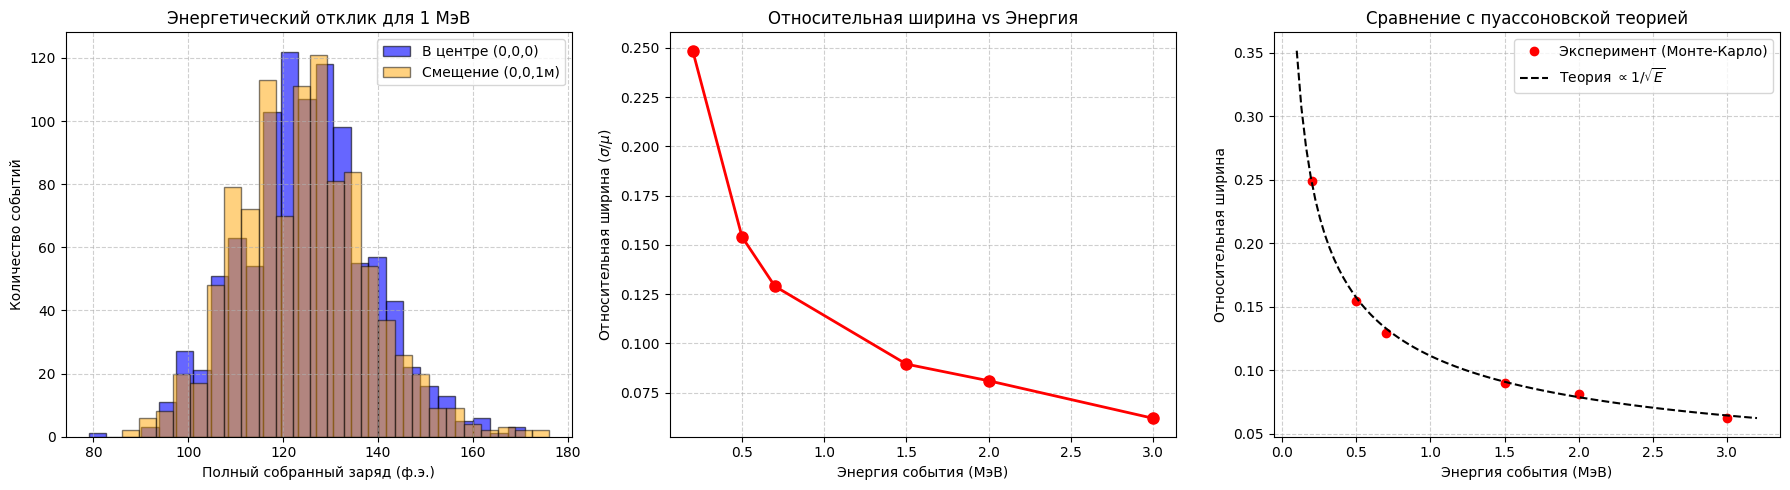

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class Source:
    def __init__(self, Y=10000):
        self.Y = Y

    def generate_photons(self, E):
        num_photons = int(round(self.Y * E))
        z = np.random.uniform(-1.0, 1.0, size=num_photons)
        phi = np.random.uniform(0.0, 2 * np.pi, size=num_photons)
        sin_theta = np.sqrt(1.0 - z**2)
        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        return np.stack([x, y, z], axis=1).astype(np.float32)


class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmt_coordinates = self._generate_uniform_pmts()

    def _generate_uniform_pmts(self):
        points = []
        phi = np.pi * (5.0**0.5 - 1.0)
        for i in range(self.N):
            y = 1 - (i / float(self.N - 1)) * 2
            radius_at_y = np.sqrt(1 - y * y)
            theta = phi * i
            x = np.cos(theta) * radius_at_y
            z = np.sin(theta) * radius_at_y
            points.append([x * self.R, y * self.R, z * self.R])
        return np.array(points, dtype=np.float32)

    def find_pmt_for_points_vectorized(self, hit_points):
        diff = hit_points[:, np.newaxis, :] - self.pmt_coordinates[np.newaxis, :, :]
        distances = np.linalg.norm(diff, axis=2)

        min_indices = np.argmin(distances, axis=1)
        min_distances = distances[np.arange(len(hit_points)), min_indices]

        pmt_indices = np.where(min_distances <= self.r, min_indices, -1)
        return pmt_indices

    def simulate_event(self, source_pos, directions):
        source_pos = np.array(source_pos, dtype=np.float32)
        b = 2.0 * np.dot(directions, source_pos)
        c = np.sum(source_pos**2) - self.R**2
        D = b**2 - 4.0 * c
        t = (-b + np.sqrt(D)) / 2.0

        hit_points = source_pos + directions * t[:, np.newaxis]
        pmt_indices = self.find_pmt_for_points_vectorized(hit_points)

        valid_hits = pmt_indices[pmt_indices != -1]

        if len(valid_hits) == 0:
            return 0

        photoelectrons = np.random.poisson(lam=self.a, size=len(valid_hits))
        return int(np.sum(photoelectrons))

detector = Detector(R=2.0, N=40, r=0.1, a=0.5)
source = Source(Y=10000)
n_events = 1000

# 1. 1000 событий с энергией 1 МэВ в центре
print("Запуск симуляции для 1 МэВ в центре...")
charges_1MeV_center = []
for _ in range(n_events):
    dirs = source.generate_photons(E=1.0)
    charge = detector.simulate_event([0.0, 0.0, 0.0], dirs)
    charges_1MeV_center.append(charge)

charges_1MeV_center = np.array(charges_1MeV_center)

# 2. Зависимость относительной ширины от энергии (в центре)
energies = [0.2, 0.5, 0.7, 1.5, 2.0, 3.0]
resolutions = []

print("\nЗапуск симуляции для сканирования по энергиям...")
for E in energies:
    charges_E = [detector.simulate_event([0.0, 0.0, 0.0], source.generate_photons(E)) for _ in range(n_events)]
    charges_E = np.array(charges_E)

    mean = np.mean(charges_E)
    std = np.std(charges_E)
    res = std / mean
    resolutions.append(res)
    print(f"Энергия: {E:>3} МэВ | Среднее: {mean:>6.1f} | СКО: {std:>5.1f} | Относ. ширина (sig/mu): {res:.4f}")

# 3. Смещение источника на 1 метр по оси Z (для 1 МэВ)
print("\nЗапуск симуляции для смещенного источника (Z = 1.0 м)...")
charges_1MeV_shifted = []
for _ in range(n_events):
    dirs = source.generate_photons(E=1.0)
    charge = detector.simulate_event([0.0, 0.0, 1.0], dirs)
    charges_1MeV_shifted.append(charge)

charges_1MeV_shifted = np.array(charges_1MeV_shifted)

mean_center = np.mean(charges_1MeV_center)
mean_shifted = np.mean(charges_1MeV_shifted)
diff_pct = abs(mean_center - mean_shifted) / mean_center * 100

print(f"\nРезультаты смещения источника:")
print(f"Среднее в центре: {mean_center:.2f}")
print(f"Среднее при смещении Z=1м: {mean_shifted:.2f}")
print(f"Изменение среднего значения: {diff_pct:.3f}%")

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# График 1: Распределение заряда для 1 МэВ в центре и при смещении
axs[0].hist(charges_1MeV_center, bins=25, alpha=0.6, color='blue', label='В центре (0,0,0)', edgecolor='black')
axs[0].hist(charges_1MeV_shifted, bins=25, alpha=0.5, color='orange', label='Смещение (0,0,1м)', edgecolor='black')
axs[0].set_title("Энергетический отклик для 1 МэВ")
axs[0].set_xlabel("Полный собранный заряд (ф.э.)")
axs[0].set_ylabel("Количество событий")
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.6)

# График 2: Зависимость относительной ширины от энергии
axs[1].plot(energies, resolutions, 'o-', color='red', linewidth=2, markersize=8)
axs[1].set_title("Относительная ширина vs Энергия")
axs[1].set_xlabel("Энергия события (МэВ)")
axs[1].set_ylabel("Относительная ширина ($\sigma / \mu$)")
axs[1].grid(True, linestyle='--', alpha=0.6)

# График 3: Проверка теоретического закона 1/sqrt(E)
fitted_E = np.linspace(0.1, 3.2, 100)
k = resolutions[0] * np.sqrt(energies[0])
theoretical_curve = k / np.sqrt(fitted_E)

axs[2].plot(energies, resolutions, 'o', color='red', label='Эксперимент (Монте-Карло)')
axs[2].plot(fitted_E, theoretical_curve, '--', color='black', label=r'Теория $\propto 1/\sqrt{E}$')
axs[2].set_title("Сравнение с пуассоновской теорией")
axs[2].set_xlabel("Энергия события (МэВ)")
axs[2].set_ylabel("Относительная ширина")
axs[2].legend()
axs[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()
